In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

# Read the CSV file
df = pd.read_csv("Life Expectancy Data.csv")

# Remove unwanted spaces from column names
df.columns = df.columns.str.strip()

# Check the dataset
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())


Dataset shape: (2938, 22)

Column names:
['Country', 'Year', 'Status', 'Life expectancy', 'Adult Mortality', 'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B', 'Measles', 'BMI', 'under-five deaths', 'Polio', 'Total expenditure', 'Diphtheria', 'HIV/AIDS', 'GDP', 'Population', 'thinness  1-19 years', 'thinness 5-9 years', 'Income composition of resources', 'Schooling']


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [2]:

# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Select the final year of the dataset
data_2015 = df[df["Year"] == 2015].copy()

# Keep records with available life expectancy
data_2015 = data_2015.dropna(
    subset=["Life expectancy"]
)

print("\nRecords available:", len(data_2015))
print("Countries:", data_2015["Country"].nunique())

display(data_2015.head())


Missing values:
Country                              0
Year                                 0
Status                               0
Life expectancy                     10
Adult Mortality                     10
infant deaths                        0
Alcohol                            194
percentage expenditure               0
Hepatitis B                        553
Measles                              0
BMI                                 34
under-five deaths                    0
Polio                               19
Total expenditure                  226
Diphtheria                          19
HIV/AIDS                             0
GDP                                448
Population                         652
thinness  1-19 years                34
thinness 5-9 years                  34
Income composition of resources    167
Schooling                          163
dtype: int64

Records available: 183
Countries: 183


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
16,Albania,2015,Developing,77.8,74.0,0,4.60,364.975229,99.0,0,...,99.0,6.00,99.0,0.1,3954.227830,28873.0,1.2,1.3,0.762,14.2
32,Algeria,2015,Developing,75.6,19.0,21,NaN,0.000000,95.0,63,...,95.0,NaN,95.0,0.1,4132.762920,39871528.0,6.0,5.8,0.743,14.4
48,Angola,2015,Developing,52.4,335.0,66,NaN,0.000000,64.0,118,...,7.0,NaN,64.0,1.9,3695.793748,2785935.0,8.3,8.2,0.531,11.4
64,Antigua and Barbuda,2015,Developing,76.4,13.0,0,NaN,0.000000,99.0,0,...,86.0,NaN,99.0,0.2,13566.954100,NaN,3.3,3.3,0.784,13.9


Histogram statistics
Count: 183
Mean: 71.62
Median: 73.9
Standard deviation: 8.12
Minimum: 51.0
Maximum: 88.0
Skewness: -0.49


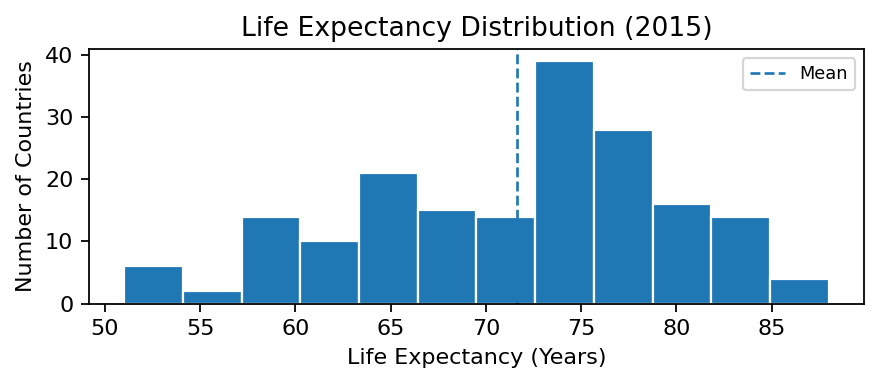

In [3]:

# Select variable for histogram
life = data_2015["Life expectancy"]

# Calculate descriptive statistics
print("Histogram statistics")
print("Count:", life.count())
print("Mean:", round(life.mean(), 2))
print("Median:", round(life.median(), 2))
print("Standard deviation:", round(life.std(), 2))
print("Minimum:", life.min())
print("Maximum:", life.max())
print("Skewness:", round(life.skew(), 2))

# Create histogram
fig, ax = plt.subplots(figsize=(5.6, 2.5), dpi=160)

ax.hist(
    life,
    bins=12,
    edgecolor="white"
)

ax.axvline(
    life.mean(),
    linestyle="--",
    linewidth=1.2,
    label="Mean"
)

ax.set_title("Life Expectancy Distribution (2015)")
ax.set_xlabel("Life Expectancy (Years)")
ax.set_ylabel("Number of Countries")
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()


Observations: 154
Pearson correlation (log GDP): 0.521
Spearman correlation: 0.568


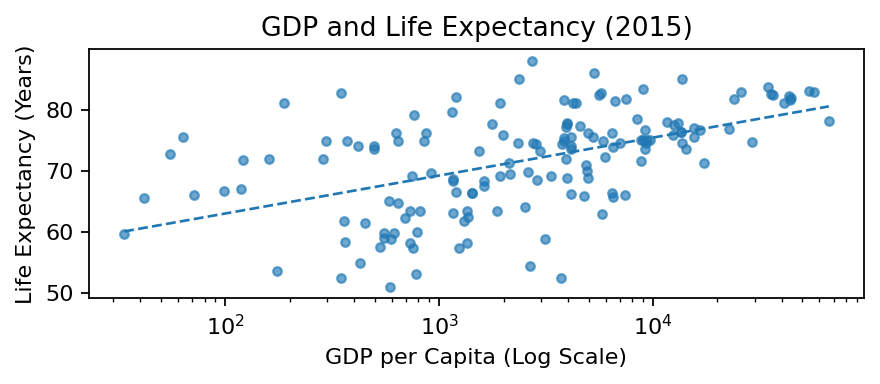

In [4]:

# Keep observations with both measurements
gdp_data = data_2015[
    ["GDP", "Life expectancy"]
].dropna().copy()

# A logarithmic axis requires positive GDP values
gdp_data = gdp_data[gdp_data["GDP"] > 0]

# Log transformation for analysis
gdp_data["log10_GDP"] = np.log10(gdp_data["GDP"])

# Correlation statistics
pearson_r = gdp_data["log10_GDP"].corr(
    gdp_data["Life expectancy"]
)

spearman_r = gdp_data["GDP"].corr(
    gdp_data["Life expectancy"],
    method="spearman"
)

print("Observations:", len(gdp_data))
print("Pearson correlation (log GDP):",
      round(pearson_r, 3))
print("Spearman correlation:",
      round(spearman_r, 3))

# Create scatter plot
fig, ax = plt.subplots(figsize=(5.6, 2.5), dpi=160)

ax.scatter(
    gdp_data["GDP"],
    gdp_data["Life expectancy"],
    alpha=0.65,
    s=15
)

# Example fitted linear trend in log-GDP space
slope, intercept = np.polyfit(
    gdp_data["log10_GDP"],
    gdp_data["Life expectancy"],
    1
)

x_log = np.linspace(
    gdp_data["log10_GDP"].min(),
    gdp_data["log10_GDP"].max(),
    100
)

ax.plot(
    10 ** x_log,
    slope * x_log + intercept,
    linestyle="--",
    linewidth=1.2
)

ax.set_xscale("log")
ax.set_title("GDP and Life Expectancy (2015)")
ax.set_xlabel("GDP per Capita (Log Scale)")
ax.set_ylabel("Life Expectancy (Years)")

plt.tight_layout()
plt.show()



 Developing
Observations: 151
Mean: 69.69
Median: 71.6
Q1: 64.6
Q3: 75.5
IQR: 10.9

 Developed
Observations: 32
Mean: 80.71
Median: 81.55
Q1: 78.6
Q3: 82.72
IQR: 4.12


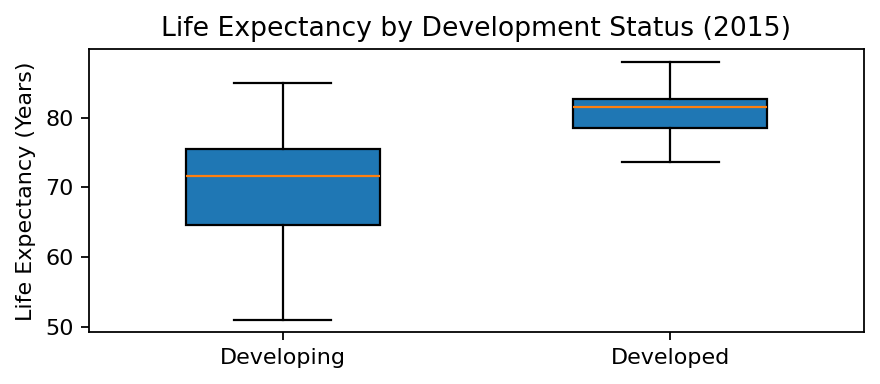

In [5]:

# Separate the development status groups
statuses = ["Developing", "Developed"]

groups = [
    data_2015.loc[
        data_2015["Status"] == status,
        "Life expectancy"
    ].dropna()
    for status in statuses
]

# Print group statistics
for status, values in zip(statuses, groups):
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    print("\n", status)
    print("Observations:", len(values))
    print("Mean:", round(values.mean(), 2))
    print("Median:", round(values.median(), 2))
    print("Q1:", round(q1, 2))
    print("Q3:", round(q3, 2))
    print("IQR:", round(iqr, 2))

# Create the box plot
fig, ax = plt.subplots(figsize=(5.6, 2.5), dpi=160)

ax.boxplot(
    groups,
    widths=0.5,
    patch_artist=True
)

ax.set_xticks([1, 2], statuses)
ax.set_title("Life Expectancy by Development Status (2015)")
ax.set_ylabel("Life Expectancy (Years)")

plt.tight_layout()
plt.show()
